# 05 Model selection: metrics, cross-validation and grid search

This notebook trains the six models from `implementations.py` on the cleaned data and
compares them with **stratified 5-fold cross-validation**. It uses the modules at the repo root:

| Module | What it gives us |
|---|---|
| `metrics.py` | accuracy, precision, recall, F1, `best_f1_threshold` |
| `cross_validation.py` | `build_k_indices`, `cross_validation`, in-fold under/oversampling |
| `grid_search.py` | `grid_search` over a hyperparameter grid, same folds for every combination |

**Data:** `dataset/prepared/clean_full.npz`. This is the cleaned training set with the *original* class
distribution (about 9% positives) and standardized features. We do **not** use the pre-oversampled
datasets here; section 7 shows why.

**Hyperparameter grids:** for MSE GD and regularized logistic regression we use the same grids as
notebooks 03 and 04, so the numbers in the report are directly comparable. Unlike those notebooks,
which score each configuration on a single 80/20 split, we report the mean ± std over 5 folds.

**Metric:** F1 on the positive class (AIcrowd metric). Every model outputs a score, and the decision
threshold is tuned for F1 on the out-of-fold scores.

Full run time: about 1 hour on a laptop (most of it in sections 5 and 6).

In [1]:
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

PROJECT_ROOT = Path.cwd().resolve().parent
if not (PROJECT_ROOT / "implementations.py").exists():
    PROJECT_ROOT = Path.cwd().resolve()
sys.path.insert(0, str(PROJECT_ROOT))

from cross_validation import (
    build_k_indices,
    cross_validation,
    fit_model,
    predict_scores,
    random_oversample,
    random_undersample,
    train_test_indices,
)
from grid_search import format_params, grid_search, load_prepared, print_results
from metrics import best_f1_threshold, compute_metrics, predict_labels

# NumPy 2.0 with Apple's Accelerate BLAS emits spurious "divide by zero / overflow /
# invalid value encountered in matmul" warnings on perfectly finite data.
# The results are correct, so we silence them.
warnings.filterwarnings("ignore", message=".*encountered in matmul")

K_FOLD = 5
SEED = 1

# Plot style: categorical colors in fixed order, thin lines, recessive grid.
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
plt.rcParams.update({
    "figure.figsize": (8, 4.5),
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "lines.linewidth": 2,
    "font.size": 10,
})

In [2]:
y, tx = load_prepared(PROJECT_ROOT / "dataset/prepared/clean_full.npz")
N, D = tx.shape

print(f"tx: {tx.shape} (bias column + {D - 1} features)")
print(f"positives: {y.sum()} / {N} = {y.mean():.2%}")
print(f"feature means in [{tx[:, 1:].mean(0).min():.1e}, {tx[:, 1:].mean(0).max():.1e}], "
      f"stds in [{tx[:, 1:].std(0).min():.3f}, {tx[:, 1:].std(0).max():.3f}]  -> already standardized")

tx: (328135, 155) (bias column + 154 features)
positives: 28975 / 328135 = 8.83%
feature means in [-7.4e-09, 1.0e+00], stds in [0.003, 1.000]  -> already standardized


## 1. Why accuracy is not enough

With about 9% positives, a model that **always predicts "no heart disease"** already gets about 91% accuracy.
F1 is 0 for that model, which is why we select models on F1.

In [3]:
baselines = {
    "always 0": np.zeros_like(y),
    "always 1": np.ones_like(y),
    "random (p = 0.5)": (np.random.default_rng(SEED).random(N) < 0.5).astype(int),
}
print(f"{'predictor':<18} {'accuracy':>8} {'precision':>9} {'recall':>6} {'F1':>6}")
for name, y_pred in baselines.items():
    m = compute_metrics(y, y_pred)
    print(f"{name:<18} {m['accuracy']:>8.4f} {m['precision']:>9.4f} {m['recall']:>6.4f} {m['f1']:>6.4f}")

predictor          accuracy precision recall     F1
always 0             0.9117    0.0000 0.0000 0.0000
always 1             0.0883    0.0883 1.0000 0.1623
random (p = 0.5)     0.4992    0.0885 0.5024 0.1505


## 2. Stratified folds

`build_k_indices` splits **every** row into exactly one fold (no rows dropped), and with
`stratified=True` each fold keeps the same positive rate. Below we compare it with a plain random split.

In [4]:
k_indices = build_k_indices(y, K_FOLD, seed=SEED, stratified=True)
k_indices_plain = build_k_indices(y, K_FOLD, seed=SEED, stratified=False)

print(f"{'fold':>4} {'size':>7} {'pos. rate (stratified)':>23} {'pos. rate (plain)':>18}")
for k in range(K_FOLD):
    print(f"{k:>4} {len(k_indices[k]):>7} {y[k_indices[k]].mean():>23.4%} {y[k_indices_plain[k]].mean():>18.4%}")

all_idx = np.concatenate(k_indices)
assert len(all_idx) == N == len(np.unique(all_idx)), "folds must partition the data"
print("\nEvery row is in exactly one fold.")

fold    size  pos. rate (stratified)  pos. rate (plain)
   0   65627                 8.8302%            8.9155%
   1   65627                 8.8302%            8.7723%
   2   65627                 8.8302%            8.7327%
   3   65627                 8.8302%            8.7997%
   4   65627                 8.8302%            8.9308%

Every row is in exactly one fold.


## 3. Least squares baseline, and why the threshold matters

Least squares regresses on y ∈ {0, 1}, so its score `tx @ w` is roughly a probability. The usual
threshold of 0.5 almost never predicts a positive. Tuning the threshold for F1 makes a big difference.

In [5]:
ls_tuned = cross_validation(y, tx, "least_squares", {}, k_indices)
ls_fixed = cross_validation(y, tx, "least_squares", {}, k_indices, threshold=0.5)

for name, r in [("threshold = 0.5", ls_fixed), (f"tuned ({ls_tuned['threshold']:.3f})", ls_tuned)]:
    print(f"{name:<18} F1 = {r['f1_mean']:.4f} ± {r['f1_std']:.4f}   "
          f"precision = {r['precision_mean']:.4f}   recall = {r['recall_mean']:.4f}   "
          f"accuracy = {r['accuracy_mean']:.4f}")

threshold = 0.5    F1 = 0.0894 ± 0.0040   precision = 0.6642   recall = 0.0479   accuracy = 0.9138
tuned (0.210)      F1 = 0.4105 ± 0.0062   precision = 0.3349   recall = 0.5301   accuracy = 0.8655


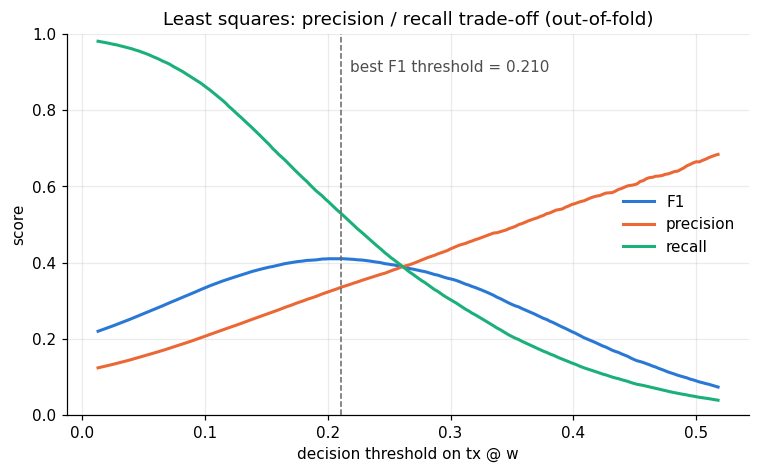

In [6]:
# F1 / precision / recall as a function of the threshold, on the out-of-fold scores.
scores = ls_tuned["oof_scores"]
thresholds = np.linspace(np.quantile(scores, 0.30), np.quantile(scores, 0.995), 200)
curves = np.array([
    [compute_metrics(y, predict_labels(scores, t))[name] for name in ("f1", "precision", "recall")]
    for t in thresholds
])

fig, ax = plt.subplots()
for (label, color), values in zip([("F1", BLUE), ("precision", ORANGE), ("recall", AQUA)], curves.T):
    ax.plot(thresholds, values, color=color, label=label)
best_thr = ls_tuned["threshold"]
ax.axvline(best_thr, color="0.4", linestyle="--", linewidth=1)
ax.annotate(f"best F1 threshold = {best_thr:.3f}", (best_thr, 0.9),
            xytext=(6, 0), textcoords="offset points", color="0.3")
ax.set_xlabel("decision threshold on tx @ w")
ax.set_ylabel("score")
ax.set_ylim(0, 1)
ax.set_title("Least squares: precision / recall trade-off (out-of-fold)")
ax.legend(frameon=False, loc="center right")
plt.show()

## 4. Ridge regression: grid search over λ

`ridge_regression` minimizes MSE + λ‖w‖², with a closed-form solution, so each fit takes well under a
second. We search λ on a log scale. The shaded band is ± 1 std over the 5 folds.

In [7]:
lambdas = np.logspace(-8, 0, 17)
start = time.time()
best_ridge, ridge_results = grid_search(y, tx, "ridge_regression", {"lambda_": lambdas},
                                        k_fold=K_FOLD, seed=SEED, verbose=False)
print(f"{len(lambdas)} values of lambda x {K_FOLD} folds in {time.time() - start:.1f}s")
print_results(ridge_results, top=5)

17 values of lambda x 5 folds in 16.8s

rank               F1  accuracy  precision  recall  threshold  params
   1  0.4122 ± 0.0067    0.8648     0.3346  0.5368     0.2073  lambda_=0.001
   2  0.4119 ± 0.0066    0.8650     0.3347  0.5356     0.2087  lambda_=0.000316
   3  0.4114 ± 0.0060    0.8587     0.3254  0.5591     0.1985  lambda_=0.00316
   4  0.4109 ± 0.0066    0.8666     0.3368  0.5268     0.2116  lambda_=0.0001
   5  0.4107 ± 0.0062    0.8656     0.3351  0.5303     0.2104  lambda_=3.16e-05


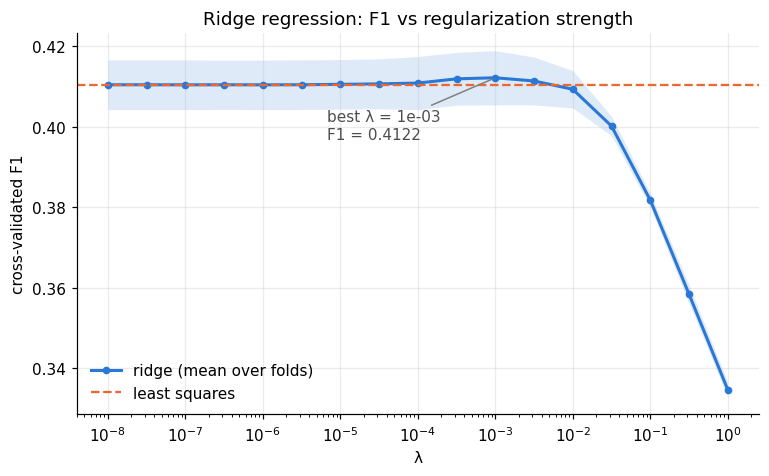

In [8]:
f1_mean = np.array([r["f1_mean"] for r in ridge_results])
f1_std = np.array([r["f1_std"] for r in ridge_results])

fig, ax = plt.subplots()
ax.fill_between(lambdas, f1_mean - f1_std, f1_mean + f1_std, color=BLUE, alpha=0.15, linewidth=0)
ax.plot(lambdas, f1_mean, color=BLUE, marker="o", markersize=4, label="ridge (mean over folds)")
ax.axhline(ls_tuned["f1_mean"], color=ORANGE, linestyle="--", linewidth=1.5, label="least squares")
best_lambda = best_ridge["params"]["lambda_"]
ax.annotate(f"best λ = {best_lambda:.0e}\nF1 = {best_ridge['f1_mean']:.4f}",
            (best_lambda, best_ridge["f1_mean"]), xytext=(-110, -40), textcoords="offset points",
            arrowprops={"arrowstyle": "-", "color": "0.5"}, color="0.3")
ax.set_xscale("log")
ax.set_xlabel("λ")
ax.set_ylabel("cross-validated F1")
ax.set_title("Ridge regression: F1 vs regularization strength")
ax.legend(frameon=False, loc="lower left")
plt.show()

## 5. MSE with gradient descent and SGD

GD and SGD minimize the same MSE as least squares, so at best they reach the least-squares F1.
The thing to check here is **step size**. GD on the MSE converges only if γ < 2/L, where L is the
largest eigenvalue of `tx.T @ tx / N`. For the logistic loss the limit is γ < 8/L.

We use the grid of notebook 03: γ ∈ {0.01, 0.05, 0.1} × max_iters ∈ {500, 1000, 5000}.
Notebook 03 also tried 10000 iterations, which gave no gain over 5000 there (F1 0.4098 vs 0.4112)
and doubles the cost, so we stop at 5000.
Notebook 03 also tried γ = 0.2, which is above the 2/L limit computed below; it diverges (the
overflow warning in notebook 03), so we leave it out. All four values of max_iters are evaluated in a
single warm-started run per fold (`cross_validation_path`): GD is deterministic, so continuing from the
500-iteration weights gives exactly the 1000-iteration weights, and the grid costs 5000 iterations
per (γ, fold) instead of 6500.

In [9]:
eigenvalues = np.linalg.eigvalsh(tx.T @ tx / N)
L, mu = eigenvalues[-1], eigenvalues[0]
print(f"largest eigenvalue L = {L:.2f}, smallest = {mu:.2e}, condition number = {L / mu:.1e}")
print(f"MSE GD stable for gamma < 2/L = {2 / L:.3f}")
print(f"logistic GD stable for gamma < 8/L = {8 / L:.3f}")

largest eigenvalue L = 19.95, smallest = 9.13e-06, condition number = 2.2e+06
MSE GD stable for gamma < 2/L = 0.100
logistic GD stable for gamma < 8/L = 0.401


The condition number is huge (some features are nearly collinear), so GD converges slowly along some
directions. It still gets close to the least-squares F1 because those directions barely affect predictions.

In [10]:
start = time.time()
best_gd, gd_results = grid_search(y, tx, "mean_squared_error_gd",
                                  {"gamma": [0.01, 0.05, 0.1], "max_iters": [500, 1000, 5000]},
                                  k_fold=K_FOLD, seed=SEED, verbose=False)
print(f"GD done in {time.time() - start:.1f}s")
print_results(gd_results, top=12)

start = time.time()
best_sgd, sgd_results = grid_search(y, tx, "mean_squared_error_sgd",
                                    {"gamma": [1e-4, 1e-3], "max_iters": [20000]},
                                    k_fold=K_FOLD, seed=SEED, verbose=False)
print(f"\nSGD done in {time.time() - start:.1f}s")
print_results(sgd_results)

GD done in 1284.0s

rank               F1  accuracy  precision  recall  threshold  params
   1  0.4115 ± 0.0068    0.8643     0.3334  0.5372     0.2083  gamma=0.1, max_iters=5000
   2  0.4112 ± 0.0069    0.8651     0.3346  0.5333     0.2092  gamma=0.05, max_iters=5000
   3  0.4108 ± 0.0063    0.8604     0.3274  0.5512      0.202  gamma=0.1, max_iters=1000
   4  0.4097 ± 0.0060    0.8650     0.3337  0.5306     0.2073  gamma=0.01, max_iters=5000
   5  0.4097 ± 0.0060    0.8650     0.3337  0.5306     0.2073  gamma=0.05, max_iters=1000
   6  0.4094 ± 0.0061    0.8658     0.3348  0.5267     0.2021  gamma=0.1, max_iters=500
   7  0.4071 ± 0.0044    0.8542     0.3176  0.5668     0.1951  gamma=0.05, max_iters=500
   8  0.3974 ± 0.0025    0.8531     0.3116  0.5486     0.1918  gamma=0.01, max_iters=1000
   9  0.3847 ± 0.0020    0.8406     0.2918  0.5643      0.178  gamma=0.01, max_iters=500

SGD done in 4.7s

rank               F1  accuracy  precision  recall  threshold  params
   1  0.3960 ± 0.

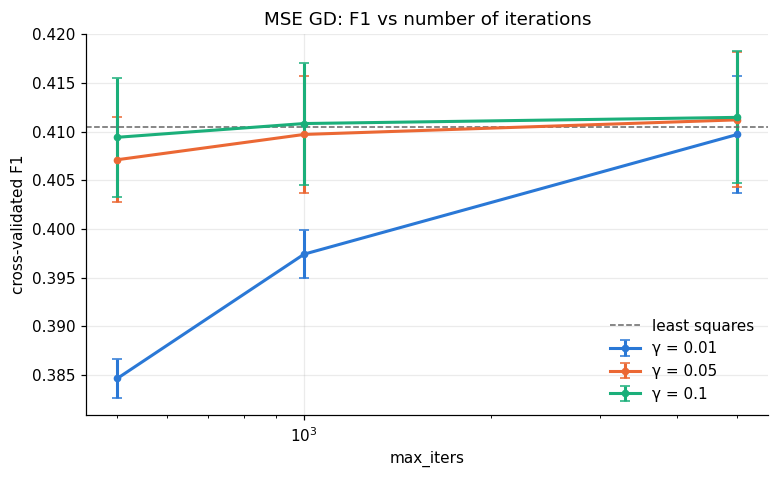

In [11]:
fig, ax = plt.subplots()
for gamma, color in zip([0.01, 0.05, 0.1], [BLUE, ORANGE, AQUA]):
    rows = sorted((r for r in gd_results if r["params"]["gamma"] == gamma),
                  key=lambda r: r["params"]["max_iters"])
    iters = [r["params"]["max_iters"] for r in rows]
    ax.errorbar(iters, [r["f1_mean"] for r in rows], yerr=[r["f1_std"] for r in rows],
                color=color, marker="o", markersize=4, capsize=3, label=f"γ = {gamma}")
ax.axhline(ls_tuned["f1_mean"], color="0.4", linestyle="--", linewidth=1, label="least squares")
ax.set_xscale("log")
ax.set_xlabel("max_iters")
ax.set_ylabel("cross-validated F1")
ax.set_title("MSE GD: F1 vs number of iterations")
ax.legend(frameon=False, loc="lower right")
plt.show()

## 6. Regularized logistic regression and class imbalance

As in notebook 04, we add the element-wise squares of the features (`x**2`) to capture simple
non-linear effects. This changes the step-size limit, so we recompute L on the expanded matrix.
Then a convergence check on one fold: training loss vs iterations for a few step sizes below 8/L.
We continue training in chunks with `initial_w = w`.

tx_sq: (328135, 309), L = 45.28, logistic GD stable for gamma < 8/L = 0.177
gamma = 0.02: loss after 1000 iterations = 0.23174
gamma = 0.05: loss after 1000 iterations = 0.22695
gamma = 0.1: loss after 1000 iterations = 0.22487


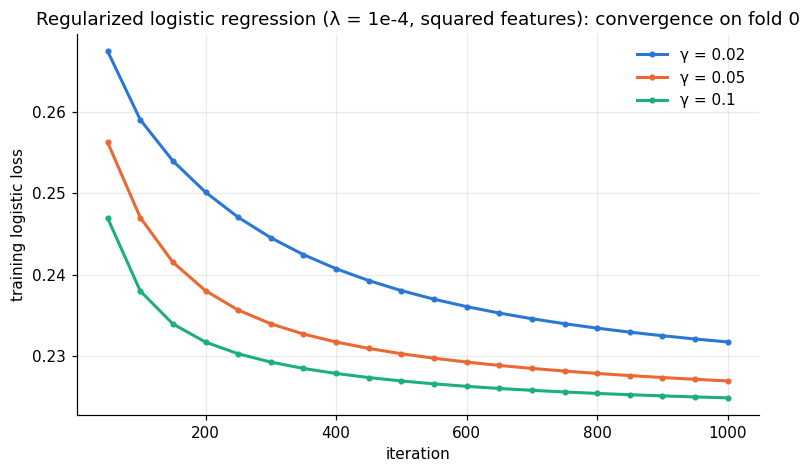

In [12]:
tx_sq = np.c_[tx, tx[:, 1:] ** 2]
L_sq = np.linalg.eigvalsh(tx_sq.T @ tx_sq / N)[-1]
print(f"tx_sq: {tx_sq.shape}, L = {L_sq:.2f}, logistic GD stable for gamma < 8/L = {8 / L_sq:.3f}")

tr_idx, _ = train_test_indices(k_indices, 0)
y_tr, tx_tr = y[tr_idx], tx_sq[tr_idx]

import implementations as impl

chunk, n_chunks = 50, 20
fig, ax = plt.subplots()
for gamma, color in zip([0.02, 0.05, 0.1], [BLUE, ORANGE, AQUA]):
    w = np.zeros(tx_sq.shape[1])
    losses = []
    for _ in range(n_chunks):
        w, loss = impl.reg_logistic_regression(y_tr, tx_tr, 1e-4, w, chunk, gamma)
        losses.append(loss)
    iters = chunk * np.arange(1, n_chunks + 1)
    ax.plot(iters, losses, color=color, marker="o", markersize=3, label=f"γ = {gamma}")
    print(f"gamma = {gamma}: loss after {iters[-1]} iterations = {losses[-1]:.5f}")
ax.set_xlabel("iteration")
ax.set_ylabel("training logistic loss")
ax.set_title("Regularized logistic regression (λ = 1e-4, squared features): convergence on fold 0")
ax.legend(frameon=False)
plt.show()

Now the grid of notebook 04: λ ∈ {1e-5, …, 1e-1} × γ ∈ {0.005, 0.01, 0.02, 0.05, 0.1} × max_iters ∈
{300, 600, 1000} (75 combinations, warm-started over max_iters).

In [ ]:
logreg_grid = {
    "lambda_": [1e-5, 1e-4, 1e-3, 1e-2, 1e-1],
    "gamma": [0.005, 0.01, 0.02, 0.05, 0.1],
    "max_iters": [300, 600, 1000],
}
start = time.time()
best_logreg, logreg_results = grid_search(y, tx_sq, "reg_logistic_regression", logreg_grid,
                                          k_fold=K_FOLD, seed=SEED, verbose=False)
print(f"{len(logreg_results)} combinations x {K_FOLD} folds in {time.time() - start:.0f}s")
print_results(logreg_results, top=10)

In [ ]:
# F1 over (lambda, gamma) at the largest max_iters.
lambdas_lr, gammas_lr = logreg_grid["lambda_"], logreg_grid["gamma"]
f1_grid = np.array([[next(r["f1_mean"] for r in logreg_results
                          if r["params"] == {"lambda_": lam, "gamma": g, "max_iters": 1000})
                     for g in gammas_lr] for lam in lambdas_lr])

fig, ax = plt.subplots(figsize=(6.5, 4.5))
im = ax.imshow(f1_grid, cmap="Blues", aspect="auto")
for i in range(len(lambdas_lr)):
    for j in range(len(gammas_lr)):
        dark = f1_grid[i, j] > f1_grid.min() + 0.6 * (f1_grid.max() - f1_grid.min())
        ax.text(j, i, f"{f1_grid[i, j]:.3f}", ha="center", va="center",
                color="white" if dark else "0.2", fontsize=9)
ax.set_xticks(range(len(gammas_lr)), [str(g) for g in gammas_lr])
ax.set_yticks(range(len(lambdas_lr)), [f"{lam:.0e}" for lam in lambdas_lr])
ax.set_xlabel("γ")
ax.set_ylabel("λ")
ax.set_title("Regularized logistic regression: cross-validated F1 (max_iters = 1000)")
ax.grid(False)
fig.colorbar(im, ax=ax, label="F1")
plt.show()

The best configuration sits on the edge of the grid (largest γ and largest max_iters), so the model has not
converged yet. Going a bit further, with γ = 0.15 (still below 8/L) and up to 3000 iterations at the best λ:

In [ ]:
start = time.time()
best_ext, ext_results = grid_search(y, tx_sq, "reg_logistic_regression",
                                    {"lambda_": [best_logreg["params"]["lambda_"]], "gamma": [0.1, 0.15],
                                     "max_iters": [1000, 2000, 3000]},
                                    k_fold=K_FOLD, seed=SEED, verbose=False)
print(f"done in {time.time() - start:.0f}s")
print_results(ext_results)

Finally, class imbalance. With the best grid configuration we compare three ways of training, using the same folds:

- **none**: train on the folds as they are (about 9% positives)
- **undersample**: keep all positives and the same number of random negatives (training folds only)
- **oversample**: duplicate random positives until the classes are balanced (training folds only)

The validation fold always keeps the real class distribution.

In [ ]:
logreg = {}
for name, resample_fn in [("none", None), ("undersample", random_undersample),
                          ("oversample", random_oversample)]:
    start = time.time()
    r = cross_validation(y, tx_sq, "reg_logistic_regression", best_logreg["params"], k_indices,
                         resample_fn=resample_fn, seed=SEED)
    logreg[name] = r
    print(f"{name:<12} F1 = {r['f1_mean']:.4f} ± {r['f1_std']:.4f}   precision = {r['precision_mean']:.4f}   "
          f"recall = {r['recall_mean']:.4f}   threshold = {r['threshold']:.4f}   ({time.time() - start:.0f}s)")

## 7. Data leakage: never oversample before splitting

`selected_random_over_dataset.npz` contains `x_train`, which was **already oversampled** (positives duplicated
up to 1/3 of the rows), and `x_train_raw`, the original rows. If we cross-validate on the oversampled
matrix, copies of the same positive end up in both the training and validation folds. The model is then
scored partly on rows it has memorized, and the validation fold no longer has the real class ratio.

We compare that with the correct procedure: split first, then oversample **only the training folds**
to the same ratio (positives = ½ × negatives).

In [ ]:
over = np.load(PROJECT_ROOT / "dataset/prepared/selected_random_over_dataset.npz", allow_pickle=True)
tx_over = np.c_[np.ones(len(over["x_train"])), over["x_train"].astype(np.float64)]
y_over = (over["y_train"] == 1).astype(int)
tx_raw = np.c_[np.ones(len(over["x_train_raw"])), over["x_train_raw"].astype(np.float64)]
y_raw = (over["y_train_raw"] == 1).astype(int)

params = {"lambda_": best_ridge["params"]["lambda_"]}

leaky = cross_validation(y_over, tx_over, "ridge_regression", params,
                         build_k_indices(y_over, K_FOLD, seed=SEED))
correct = cross_validation(y_raw, tx_raw, "ridge_regression", params,
                           build_k_indices(y_raw, K_FOLD, seed=SEED),
                           resample_fn=lambda x, y, seed: random_oversample(x, y, seed, ratio=0.5))

print(f"positives in validation folds: leaky = {y_over.mean():.1%}, correct = {y_raw.mean():.1%}\n")
print(f"oversample THEN split (leaky):   F1 = {leaky['f1_mean']:.4f} ± {leaky['f1_std']:.4f}")
print(f"split THEN oversample (correct): F1 = {correct['f1_mean']:.4f} ± {correct['f1_std']:.4f}")

## 8. Summary

In [ ]:
summary = [
    ("least squares", ls_tuned, {}),
    ("ridge regression", best_ridge, best_ridge["params"]),
    ("MSE GD", best_gd, best_gd["params"]),
    ("MSE SGD", best_sgd, best_sgd["params"]),
    ("reg. logistic (grid of nb 04)", best_logreg, best_logreg["params"]),
    ("reg. logistic (extended)", best_ext, best_ext["params"]),
    ("reg. logistic + undersample", logreg["undersample"], best_logreg["params"]),
    ("reg. logistic + oversample", logreg["oversample"], best_logreg["params"]),
]
summary.sort(key=lambda row: row[1]["f1_mean"], reverse=True)

print(f"{'model':<31} {'F1':>15} {'accuracy':>8} {'precision':>9} {'recall':>6} {'threshold':>9}  params")
for name, r, params in summary:
    print(f"{name:<31} {r['f1_mean']:.4f} ± {r['f1_std']:.4f} {r['accuracy_mean']:>8.4f} "
          f"{r['precision_mean']:>9.4f} {r['recall_mean']:>6.4f} {r['threshold']:>9.4g}  "
          f"{format_params(params)}")

In [ ]:
names = [row[0] for row in summary][::-1]
means = np.array([row[1]["f1_mean"] for row in summary])[::-1]
stds = np.array([row[1]["f1_std"] for row in summary])[::-1]

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(names, means, xerr=stds, color=BLUE, height=0.6,
        error_kw={"ecolor": "0.35", "elinewidth": 1, "capsize": 3})
for i, value in enumerate(means):
    ax.text(value + stds[i] + 0.003, i, f"{value:.3f}", va="center", color="0.25")
ax.set_xlim(means.min() - 0.03, means.max() + 0.03)
ax.set_xlabel("cross-validated F1 (mean ± std over 5 folds)")
ax.set_title("Model comparison")
ax.grid(axis="y", visible=False)
plt.show()

## 9. Conclusions

CONCLUSIONS_PLACEHOLDER